
TÜM VERİ DAĞILIMI
 label
0    15637
2     5734
1     3815
Name: count, dtype: int64

TRAIN
 label
0    10946
2     4014
1     2670
Name: count, dtype: int64

VAL
 label
0    1563
2     573
1     382
Name: count, dtype: int64

TEST
 label
0    3128
2    1147
1     763
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

Map:   0%|          | 0/17630 [00:00<?, ? examples/s]

... (6 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



📊 GENEL METRİK TABLOSU


,Accuracy,Precision,Recall,F1-score
Train,0.976687,0.976520,0.976687,0.976587
Validation,0.964654,0.964075,0.964654,0.964161
Test,0.966455,0.966115,0.966455,0.966250


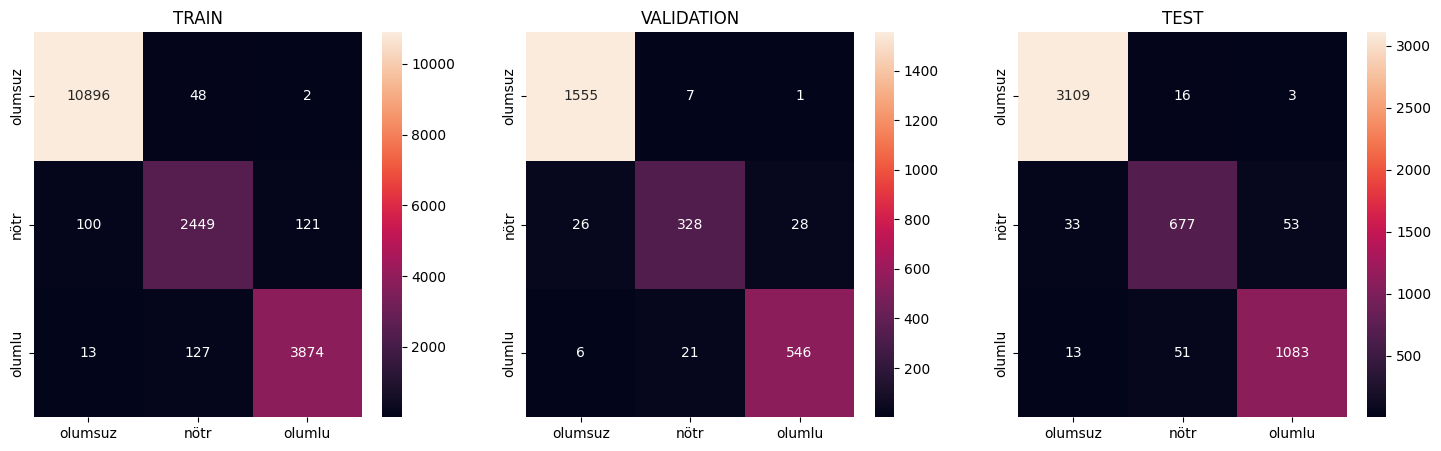

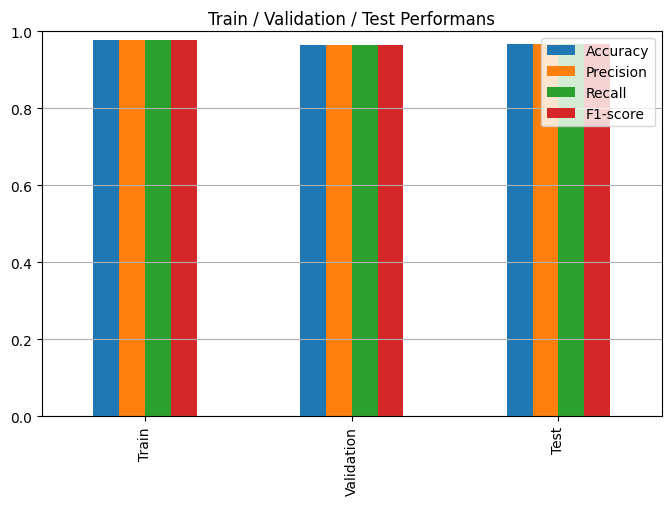

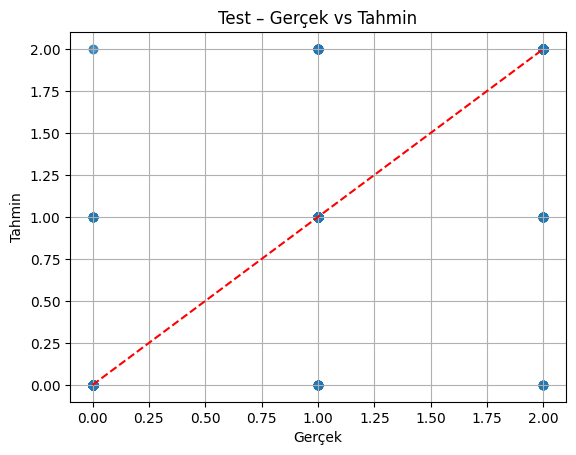

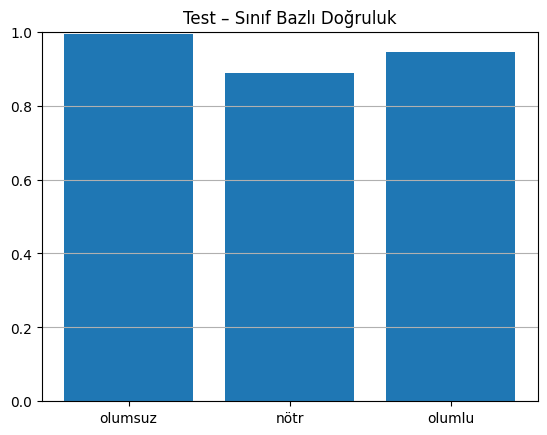

In [ ]:
# =========================================================
# 0) KURULUM
# =========================================================
!pip install -q transformers datasets accelerate

# =========================================================
# 1) KÜTÜPHANELER
# =========================================================
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

from transformers import (
    BertForSequenceClassification,
    BertTokenizerFast,
    TrainingArguments,
    Trainer
)

from datasets import Dataset

# =========================================================
# 2) VERİ SETİNİ YÜKLE (TEK CSV)
# =========================================================
df = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
df = df.rename(columns={"review": "text", "sentiment": "duygu"})
df = df[["text", "duygu"]].dropna()

# =========================================================
# 3) LABEL MAPPING
# =========================================================
label_map = {"olumsuz": 0, "nötr": 1, "olumlu": 2}

df["label"] = (
    df["duygu"]
    .astype(str).str.lower().str.replace(" ", "")
    .map(label_map)
)

df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

print("\nTÜM VERİ DAĞILIMI\n", df["label"].value_counts())

# =========================================================
# 4) %70 TRAIN – %20 TEST – %10 VAL
# =========================================================
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=2/3, stratify=temp_df["label"], random_state=42
)

print("\nTRAIN\n", train_df["label"].value_counts())
print("\nVAL\n", val_df["label"].value_counts())
print("\nTEST\n", test_df["label"].value_counts())

# =========================================================
# 5) TOKENIZER
# =========================================================
MODEL_NAME = "dbmdz/bert-base-turkish-cased"
tokenizer = BertTokenizerFast.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=48      # HIZLI
    )

train_ds = Dataset.from_pandas(train_df).map(tokenize, batched=True)
val_ds   = Dataset.from_pandas(val_df).map(tokenize, batched=True)
test_ds  = Dataset.from_pandas(test_df).map(tokenize, batched=True)

for ds in [train_ds, val_ds, test_ds]:
    ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])

train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

# =========================================================
# 6) MODEL
# =========================================================
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

# =========================================================
# 7) METRICS
# =========================================================
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="macro"),
        "recall": recall_score(labels, preds, average="macro"),
        "f1": f1_score(labels, preds, average="macro"),
    }

# =========================================================
# 8) TRAINING ARGUMENTS (≈ 3–4 SAAT)
# =========================================================
args = TrainingArguments(
    output_dir="./bert_fast",
    num_train_epochs=2,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    fp16=True,

    eval_strategy="steps",
    eval_steps=1000,
    save_steps=1000,

    logging_steps=200,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

# =========================================================
# 9) EĞİTİM
# =========================================================
trainer.train()

# =========================================================
# 10) TAHMİNLER
# =========================================================
def predict(dataset):
    return np.argmax(trainer.predict(dataset).predictions, axis=1)

y_train_true = train_df["label"].values
y_val_true   = val_df["label"].values
y_test_true  = test_df["label"].values

y_train_pred = predict(train_ds)
y_val_pred   = predict(val_ds)
y_test_pred  = predict(test_ds)

# =========================================================
# 11) METRİK TABLOSU
# =========================================================
def metric_row(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average="weighted"),
        recall_score(y_true, y_pred, average="weighted"),
        f1_score(y_true, y_pred, average="weighted")
    ]

results = pd.DataFrame(
    [
        metric_row(y_train_true, y_train_pred),
        metric_row(y_val_true, y_val_pred),
        metric_row(y_test_true, y_test_pred)
    ],
    columns=["Accuracy", "Precision", "Recall", "F1-score"],
    index=["Train", "Validation", "Test"]
)

print("\n📊 GENEL METRİK TABLOSU")
display(results)

# =========================================================
# 12) TÜM GRAFİKLER
# =========================================================

# Confusion Matrices
fig, ax = plt.subplots(1,3, figsize=(18,5))
for i, (y_t, y_p, title) in enumerate([
    (y_train_true, y_train_pred, "TRAIN"),
    (y_val_true, y_val_pred, "VALIDATION"),
    (y_test_true, y_test_pred, "TEST")
]):
    sns.heatmap(confusion_matrix(y_t, y_p), annot=True, fmt="d",
                xticklabels=["olumsuz","nötr","olumlu"],
                yticklabels=["olumsuz","nötr","olumlu"], ax=ax[i])
    ax[i].set_title(title)
plt.show()

# Performans karşılaştırma
results.plot(kind="bar", figsize=(8,5))
plt.ylim(0,1)
plt.title("Train / Validation / Test Performans")
plt.grid(axis="y")
plt.show()

# Gerçek vs Tahmin (Test)
plt.scatter(y_test_true, y_test_pred, alpha=0.4)
plt.plot([0,2],[0,2],"r--")
plt.xlabel("Gerçek")
plt.ylabel("Tahmin")
plt.title("Test – Gerçek vs Tahmin")
plt.grid()
plt.show()

# Sınıf Bazlı Doğruluk (Test)
cm = confusion_matrix(y_test_true, y_test_pred)
class_acc = cm.diagonal() / cm.sum(axis=1)
plt.bar(["olumsuz","nötr","olumlu"], class_acc)
plt.ylim(0,1)
plt.title("Test – Sınıf Bazlı Doğruluk")
plt.grid(axis="y")
plt.show()


In [ ]:
# =========================================================
# 13) DIŞ TEST SETİ (XLSX) – GÜVENLİ VE HATASIZ
# =========================================================

# === 1) XLSX DOSYASINI OKU ===
xlsx_path = "ml proje.xlsx"
ext_df = pd.read_excel(xlsx_path)

# === 2) METİN SÜTUNUNU BUL ===
if "yorum" in ext_df.columns:
    text_col = "yorum"
elif "review" in ext_df.columns:
    text_col = "review"
elif "text" in ext_df.columns:
    text_col = "text"
else:
    raise ValueError("XLSX dosyasında yorum sütunu bulunamadı")

# === 3) SADECE METİN SÜTUNU İLE DATASET OLUŞTUR ===
text_df = ext_df[[text_col]].rename(columns={text_col: "text"})
text_df = text_df.dropna().reset_index(drop=True)

print(f"\n📂 XLSX Test Örnek Sayısı: {len(text_df)}")

# === 4) DATASET ===
ext_ds = Dataset.from_pandas(text_df)

ext_ds = ext_ds.map(
    lambda x: tokenizer(
        x["text"],
        truncation=True,
        padding="max_length",
        max_length=48
    ),
    batched=True
)

ext_ds.set_format("torch", columns=["input_ids", "attention_mask"])

# === 5) MODEL TAHMİNİ ===
pred_output = trainer.predict(ext_ds)

logits = pred_output.predictions
probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
pred_labels = np.argmax(probs, axis=1)

# === 6) LABEL → METİN ===
inv_label_map = {0: "olumsuz", 1: "nötr", 2: "olumlu"}

# === 7) SONUÇLARI ORİJİNAL DF’E EKLE ===
ext_df = ext_df.loc[text_df.index].reset_index(drop=True)

ext_df["tahmin_label"] = pred_labels
ext_df["tahmin_duygu"] = [inv_label_map[i] for i in pred_labels]

ext_df["prob_olumsuz"] = probs[:, 0]
ext_df["prob_notr"]    = probs[:, 1]
ext_df["prob_olumlu"]  = probs[:, 2]

# === 8) XLSX OLARAK KAYDET ===
output_path = "bert_xlsx_tahmin_sonuclari.xlsx"
ext_df.to_excel(output_path, index=False)

print(f"\n✅ Tahminler kaydedildi: {output_path}")

# === 9) ÖRNEK GÖSTER ===
display(ext_df.head(10))



📂 XLSX Test Örnek Sayısı: 500


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



✅ Tahminler kaydedildi: bert_xlsx_tahmin_sonuclari.xlsx


,marka,ürün,yorum,beden,cinsiyet,tarih,yıldız,duygu,tahmin_label,tahmin_duygu,prob_olumsuz,prob_notr,prob_olumlu
0,mavi,Jake Pro Sport Gece Mavisi Jean Pantolon 00422...,Ürün güzel fakat yaz aylarında giyilmez çok ka...,32/30,erkek,2025-07-21,2,olumsuz,0,olumsuz,0.810782,0.173081,0.016137
1,mavi,Jake Pro Sport Gece Mavisi Jean Pantolon 00422...,İkinci defa Siyah istedim yine lacivert geldi ...,34/32,erkek,2025-07-16,5,olumlu,0,olumsuz,0.937154,0.055928,0.006918
2,mavi,Jake Pro Sport Gece Mavisi Jean Pantolon 00422...,Bayıldım harika,33/32,erkek,2025-08-19,5,olumlu,2,olumlu,0.006744,0.011984,0.981272
3,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,çok güzelmiş çok beğendim teşekkürler,27/27,kadın,2025-11-12,5,olumlu,2,olumlu,0.003926,0.034758,0.961316
4,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,rengi daha açık bir beden küçük alınabilir,33/27,kadın,2025-11-10,4,olumlu,0,olumsuz,0.871562,0.122296,0.006142
5,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,155 49 kiloyaa 25 25 beden tam oldu rengi çok ...,25/25,kadın,2025-06-16,5,olumlu,2,olumlu,0.007930,0.026280,0.965791
6,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,Ürünün fotoğrafla alakası yok 52-53-54 kiloya ...,26/25,kadın,2025-11-10,1,olumsuz,0,olumsuz,0.998826,0.000851,0.000323
7,mavi,Marcus Antrasit Smoke Jean Pantolon 8835126868,ürün güzel tavsiye ederim,36/30,erkek,2025-11-12,4,olumlu,2,olumlu,0.001250,0.007344,0.991406
8,mavi,Marcus Antrasit Smoke Jean Pantolon 8835126868,Süper tam kalıp rengi dumanlı gri,34/30,erkek,2025-11-09,5,olumlu,1,nötr,0.050177,0.835860,0.113963
9,mavi,Marcus Antrasit Smoke Jean Pantolon 8835126868,Defalarca yıkanmış solmuş gibi duruyor. Rengin...,33/32,erkek,2025-11-04,2,olumsuz,0,olumsuz,0.980196,0.017090,0.002715



🎯 Gerçek etiket bulundu: duygu

===== XLSX TEST METRİKLERİ =====
Accuracy : 0.656
Precision: 0.7694402686434436
Recall   : 0.656
F1-score : 0.6824704620006745

Detaylı tablo:
              precision    recall  f1-score   support

     olumsuz       0.39      0.89      0.55        76
        nötr       0.18      0.19      0.18        64
      olumlu       0.95      0.69      0.80       360

    accuracy                           0.66       500
   macro avg       0.51      0.59      0.51       500
weighted avg       0.77      0.66      0.68       500



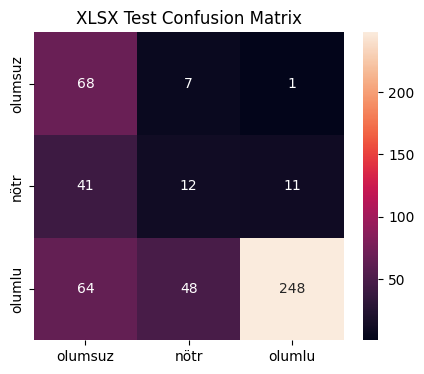

In [ ]:
# =========================================================
# 14) XLSX TEST METRİKLERİ (GERÇEK ETİKET VARSA)
# =========================================================

# === GERÇEK ETİKET SÜTUNUNU BUL ===
if "duygu" in ext_df.columns:
    gt_col = "duygu"
elif "sentiment" in ext_df.columns:
    gt_col = "sentiment"
elif "label" in ext_df.columns:
    gt_col = "label"
else:
    gt_col = None

if gt_col is not None:
    print(f"\n🎯 Gerçek etiket bulundu: {gt_col}")

    # === METİN → SAYI ===
    y_true = (
        ext_df[gt_col]
        .astype(str).str.lower().str.replace(" ", "")
        .map({"olumsuz":0, "nötr":1, "olumlu":2})
        .dropna()
        .values
    )

    y_pred = ext_df.loc[:len(y_true)-1, "tahmin_label"].values

    # === METRİKLER ===
    print("\n===== XLSX TEST METRİKLERİ =====")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, average="weighted"))
    print("Recall   :", recall_score(y_true, y_pred, average="weighted"))
    print("F1-score :", f1_score(y_true, y_pred, average="weighted"))

    print("\nDetaylı tablo:")
    print(classification_report(
        y_true, y_pred,
        target_names=["olumsuz","nötr","olumlu"]
    ))

    # === CONFUSION MATRIX ===
    plt.figure(figsize=(5,4))
    sns.heatmap(
        confusion_matrix(y_true, y_pred),
        annot=True, fmt="d",
        xticklabels=["olumsuz","nötr","olumlu"],
        yticklabels=["olumsuz","nötr","olumlu"]
    )
    plt.title("XLSX Test Confusion Matrix")
    plt.show()

else:
    print("\n⚠️ XLSX dosyasında gerçek etiket yok → metrik hesaplanamaz")


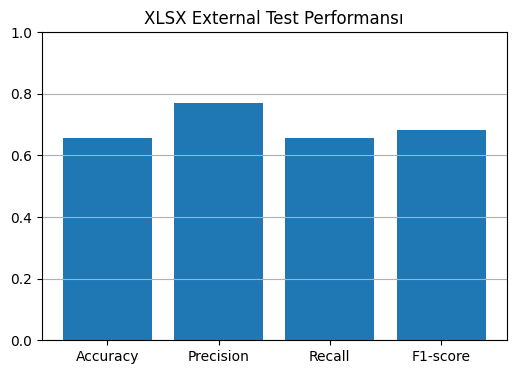

In [ ]:
# =========================================================
# GRAFİK 5: XLSX TEST METRİKLERİ
# =========================================================

if gt_col is not None:
    xlsx_metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted"),
        "Recall": recall_score(y_true, y_pred, average="weighted"),
        "F1-score": f1_score(y_true, y_pred, average="weighted")
    }

    plt.figure(figsize=(6,4))
    plt.bar(xlsx_metrics.keys(), xlsx_metrics.values())
    plt.ylim(0,1)
    plt.title("XLSX External Test Performansı")
    plt.grid(axis="y")
    plt.show()


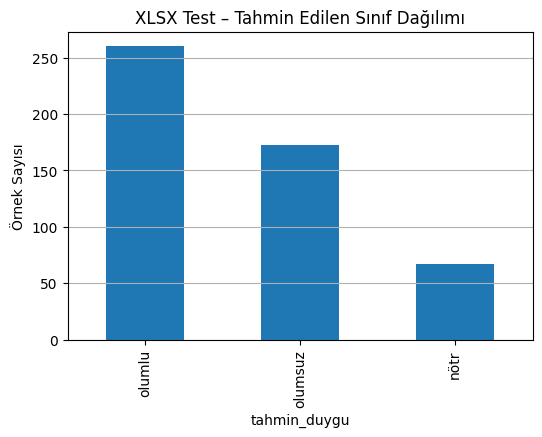

In [ ]:
# =========================================================
# GRAFİK 6: XLSX TAHMİN SINIF DAĞILIMI
# =========================================================

plt.figure(figsize=(6,4))
ext_df["tahmin_duygu"].value_counts().plot(kind="bar")
plt.ylabel("Örnek Sayısı")
plt.title("XLSX Test – Tahmin Edilen Sınıf Dağılımı")
plt.grid(axis="y")
plt.show()


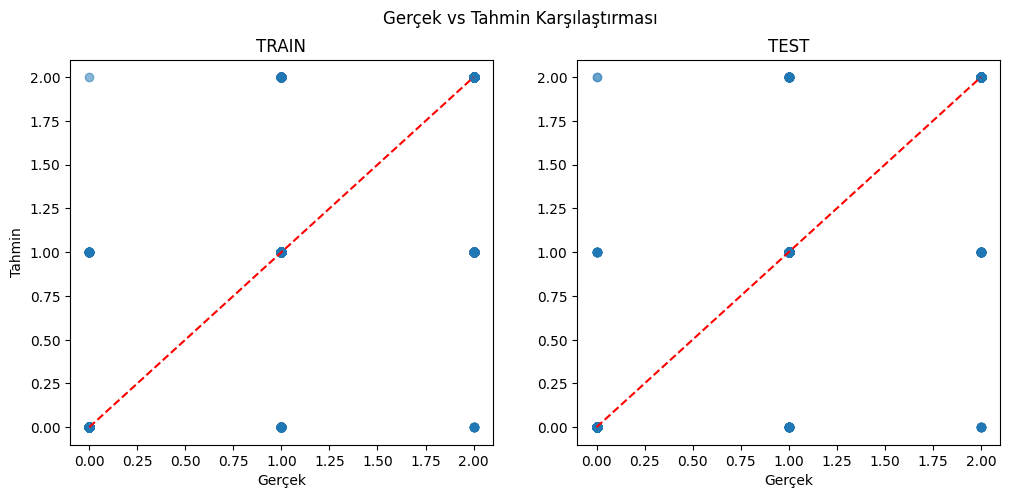

In [ ]:
# =========================================================
# GRAFİK 5: GERÇEK vs TAHMİN (TRAIN & TEST)
# =========================================================

fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].scatter(y_train_true, y_train_pred, alpha=0.3)
ax[0].plot([0,2],[0,2],"r--")
ax[0].set_title("TRAIN")
ax[0].set_xlabel("Gerçek")
ax[0].set_ylabel("Tahmin")

ax[1].scatter(y_test_true, y_test_pred, alpha=0.3)
ax[1].plot([0,2],[0,2],"r--")
ax[1].set_title("TEST")
ax[1].set_xlabel("Gerçek")

plt.suptitle("Gerçek vs Tahmin Karşılaştırması")
plt.show()


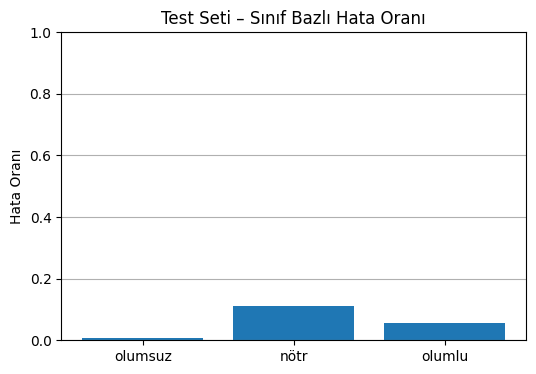

In [ ]:
# =========================================================
# GRAFİK 6: TEST HATA ORANI (SINIF BAZLI)
# =========================================================

cm = confusion_matrix(y_test_true, y_test_pred)
error_rate = 1 - (cm.diagonal() / cm.sum(axis=1))

plt.figure(figsize=(6,4))
plt.bar(["olumsuz","nötr","olumlu"], error_rate)
plt.ylim(0,1)
plt.ylabel("Hata Oranı")
plt.title("Test Seti – Sınıf Bazlı Hata Oranı")
plt.grid(axis="y")
plt.show()
